<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta6g%C3%B6rev4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

3 Boyutlu Oylama (Accumulator) işlemi gerçekleştiriliyor...
Eşik değerini aşan 0 potansiyel merkez bulundu.
Canny + Median Kenar Görüntüsü:


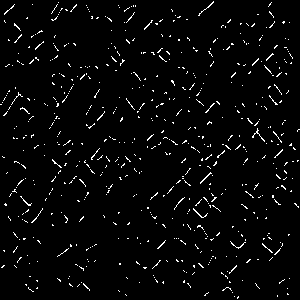

Özel 3D Hough Çember Tespiti Sonucu:


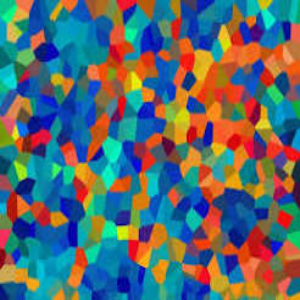

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np

# 1. Resmi yükleme ve ön işleme
img = cv2.imread('indir.jpg')
if img is None:
  print('Resim yüklenemedi. Lütfen dosya adını kontrol edin.')
else:
  # Python döngülerinin performanslı çalışabilmesi için resmi yeniden boyutlandırıyoruz
  img = cv2.resize(img, (300, 300))
  gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

  # Median filtre ile gürültü azaltma ve Canny kenar tespiti
  median_gray = cv2.medianBlur(gray, 5)
  edges = cv2.Canny(median_gray, 50, 150)
  median_edges = cv2.medianBlur(edges, 3)

  height, width = median_edges.shape

  # 2. Çember Parametreleri ve Sin/Cos Ön Hesaplama (Lookup Tables)
  min_radius = 10
  max_radius = 50
  # Yarıçap aralığı (adım boyutu 3 seçilerek hız artırılmıştır)
  radii = np.arange(min_radius, max_radius, 3)
  num_radii = len(radii)

  # Açılar (0 ile 360 derece arası, 10'ar derece adımlarla)
  thetas = np.deg2rad(np.arange(0, 360, 10))
  num_thetas = len(thetas)

  # İSTEK: Sin ve Cos değerlerini baştan hesaplayıp bellekte tutma (Lookup Table)
  cos_thetas = np.cos(thetas)
  sin_thetas = np.sin(thetas)

  # 3. 3 Boyutlu Oylama Matrisini (Accumulator) Oluşturma
  # Boyutlar: Y ekseni (merkez y), X ekseni (merkez x), R (yarıçap indexi)
  accumulator = np.zeros((height, width, num_radii), dtype=np.uint32)

  # Kenar piksel koordinatlarını alma
  edge_y, edge_x = np.nonzero(median_edges)

  # 4. Oylama İşleminin Açıkça Gösterilmesi (Voting Process)
  print('3 Boyutlu Oylama (Accumulator) işlemi gerçekleştiriliyor...')
  for i in range(len(edge_x)):
    x = edge_x[i]
    y = edge_y[i]

    # Her bir yarıçap ve açı kombinasyonu için olası merkez (xc, yc) hesaplanır
    for r_idx, r in enumerate(radii):
      for t_idx in range(num_thetas):
        # Parametrik çember denklemi:
        # xc = x - r * cos(theta)
        # yc = y - r * sin(theta)
        xc = int(np.round(x - r * cos_thetas[t_idx]))
        yc = int(np.round(y - r * sin_thetas[t_idx]))

        # Bulunan merkez koordinatları görüntü sınırları içindeyse oy verilir
        if 0 <= xc < width and 0 <= yc < height:
          accumulator[yc, xc, r_idx] += 1

  # 5. Eşik Değeri Belirleme ve Çemberleri Çizme
  threshold = (
      25  # Oylama matrisindeki minimum oy eşik değeri (resme göre ayarlanabilir)
  )
  img_circles = img.copy()

  # Akümülatörde eşiği aşan (yc, xc, r_idx) koordinatlarını bulma
  y_indices, x_indices, r_indices = np.where(accumulator > threshold)

  print(f'Eşik değerini aşan {len(x_indices)} potansiyel merkez bulundu.')

  # Bulunan çemberleri orijinal resim üzerine çizme
  for yc, xc, r_idx in zip(y_indices, x_indices, r_indices):
    r = radii[r_idx]

    # Çemberin merkezini Kırmızı nokta ile işaretle (BGR: 0, 0, 255)
    cv2.circle(img_circles, (xc, yc), 2, (0, 0, 255), 3)

    # Çemberin çevresini Mavi renk ile çiz (BGR: 255, 0, 0)
    cv2.circle(img_circles, (xc, yc), r, (255, 0, 0), 2)

  # Sonuçları Colab üzerinden görselleştirme
  print('Canny + Median Kenar Görüntüsü:')
  cv2_imshow(median_edges)

  print('Özel 3D Hough Çember Tespiti Sonucu:')
  cv2_imshow(img_circles)